#### FFW SG2 - Motion Executor (EEF markers + bring-up sequence)

Same scene as `sim_joint_controller_sg2_teleop_with_table.ipynb` -- floor, robot and the table
from `xml/table.xml` -- with the EEF markers of `sim_eef_controller_sg2_teleop.ipynb`: drag the
two wrist gizmos and each arm runs its own small DLS IK solve toward its gizmo. On top of that sits a **motion executor**
(`package/motion_executor.py`): a whole-arm move is no longer written into MuJoCo the instant it
is asked for, it is **planned as a minimum-jerk trajectory first** and then played out one
position command per control cycle.

Workflow: drag the markers to put the robot wherever you like, then pick a command in the
**SG2 Joint Marker Command** window and watch the executor drive the arms there smoothly.

| row | what it does |
|---|---|
| `Motion` | `bring_up` = start -> step1 -> step2 (the real robot's power-on sequence) / `grip_close` / `grip_open` = drive both grippers, nothing else moves / `shut_down` = open the grippers, lift the wrists clear, then fold back through step2 -> step1 -> start / `stop` = cancel where it is |
| `Preset` | `zero` / `init` -- also routed through the executor, so a preset is a planned move, not a jump / `sync` cancels the executor and re-seeds the markers |
| `File` | `save` / `load` the pose as `qpos/sg2_joint_qpos.json` (a load is executed, not jumped) |
| `Collision` | signed-distance collision warning -- robot vs robot **and** robot vs table, report only, nothing is corrected |
| `EEF` | draw both wrist frames and print their position / RPY |
| `Show` | which wrist gizmo stays live -- `all` / `left` / `right` |

**Who owns the joints when.** The gizmo IK and the executor must never write the same joints on
the same tick, so the loop hands ownership to exactly one of them: while the executor is active
the IK solve is skipped and the gizmos are re-seeded onto the wrists it is moving; when it is
idle the gizmos are live again. That is why `bring_up` does not fight the marker you just
dragged.

**The output stage keeps the same order as the real notebook**
(`real_joint_controller_sg2_teleop.ipynb`, cell 14):

    write the target into env -> apply_sg2_joint_rate_limit -> np.clip -> env.forward

Moving to hardware only adds
`pub_robot.send(obj=get_qmsg_from_qpos(qpos=q_use, q_msg_layout=q_msg_layout))` after each tick.

**`shut_down` is not just `bring_up` reversed.** Folding the arms in from wherever they happen to
be can drag a closed gripper through whatever it was holding, so two pre-steps run first:

1. **open both grippers** (`gripper_?_joint1` -> 0.0; every other joint held still)
2. **lift both wrists straight up** to the height they have at the `step2` waypoint -- x, y and
   orientation unchanged, solved with the same per-arm IK the gizmos use

Neither can be a stored constant: both depend on the pose the robot is in when the command is
given. `build_sg2_shut_down_goals` computes them at command time, and the lift is skipped when
the wrists are already high enough (or when no `ik_solvers` is passed).

**The bring-up waypoints are stored by joint name, never as bare 19-vectors.**
`command_joint_names` starts with `lift_joint, head_joint1, head_joint2` while
`ffw_sg2_follower_initial_positions.yaml` starts at `arm_l_joint1` and carries 8 values per arm
(7 joints + gripper). A positional copy of that yaml lands `1.57` in the lift slide, whose limit
is `-0.5 ~ 0.0 m`.


In [1]:
%run ../package/init_project.py

import numpy as np

from ri_motion_v5_package.init_scripts.init_ipython_setup import *
from ri_motion_v5_package.init_scripts.init_qt import *
from ri_motion_v5_package.mujoco_sim import *
from ri_motion_v5_package.kinematics import *
from ri_motion_v5_package.utility import *
from ri_motion_v5_package.qt import *
from utils import *
from package.joint_control import *        # not `from joint_control import *`: IPython's %run puts
from package.joint_marker_control import * # PACKAGE_DIR on sys.path only during the run
from package.joint_marker_real import *    # speed limits + apply_sg2_joint_rate_limit
from package.motion_executor import *      # min-jerk planner, SG2MotionExecutor, bring-up waypoints

app = get_qt_app()


[ffw_sg2_vr_teleoperation] initialized.
 - PROJECT_DIR: /Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation
Basic packages initialized.
 import numpy as np
 import matplotlib.pyplot as plt
 import scipy as sp
 from PIL import Image
[ipython] settings (retina, inline, qt) initialized.
[numpy] settings initialized.
[matplotlib] settings initialized.
[qt] package initialized.


In [2]:
xml_path = merge_mjcfs(
    included_mjcf_files = [
        str(FLOOR_XML_PATH),
        str(SG2_XML_PATH),
        str(SG2_PROJECT_XML_DIR / "table.xml"),  # same scene as sim_joint_controller_sg2_teleop_with_table
    ],
    output_xml_path = str(SG2_SCENE_XML_PATH),)
env = MuJoCoParser(rel_xml_path=xml_path,verbose=False)
env.reset()
env.set_p("base_link","body",(0.0,0.0,0.01))

# Bend the elbows into a natural pose so both wrists start away from IK singularities.
env.forward(
    q           = [np.deg2rad(-90.0),np.deg2rad(-90.0)],
    joint_names = ["arm_l_joint4","arm_r_joint4"],)

# Same joint set the real robot takes over ZMQ: lift + head + both arms + both gripper drivers.
# The executor works in this order throughout; note it differs from the arm-only IK joint order.
command_joint_names = filter_existing_joint_names(
    env,
    list(SG2_REAL_COMMAND_JOINT_NAMES)
    + [SG2_GRIPPER_DRIVER_JOINT_NAMES[hand_type] for hand_type in SG2_HAND_TYPES],)
print(f"command joints ({len(command_joint_names)}): {command_joint_names}")

[merge_mjcfs] Merging [3] MJCF files:
  - [0] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/floor_simple_white.xml]
  - [1] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/ffw_sg2.xml]
  - [2] [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/table.xml]
[merge_mjcfs] Saved merged XML to:[/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml]
MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
command joints (19): ['lift_joint', 'head_joint1', 'head_joint2', 'arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7', 'arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7', 'gripper_l_joint1', 'gripper_r_joint1']


In [3]:
# One small (non-collision-aware) DLS IK solver per arm, each restricted to that arm's joints.
ik_solvers,arm_joint_names = create_sg2_arm_ik_solvers(
    env                = env,
    mujoco_parser_cls  = MuJoCoParser,
    body_ik_solver_cls = BodyPositionIKSolverRevPriBase,)
for hand_type in SG2_HAND_TYPES:
    print(f"{hand_type} arm IK joints ({len(arm_joint_names[hand_type])}): {arm_joint_names[hand_type]}")

# Collision is only monitored here: signed distances are reported, never corrected.
# The candidate pairs are "one geom on the robot vs any other collision geom", so with
# table.xml merged into the scene the robot-vs-table pairs come along for free -- the
# same call now covers self-collision AND the table.
collision_geom_pairs,collision_candidate_info = create_sg2_collision_candidate_geom_pairs(
    env               = env,
    init_exclude_dist = 0.05,)
print_sg2_collision_candidate_summary(collision_candidate_info)

# Split the candidates into self-collision and robot-vs-table, so it is visible that the
# table actually entered the set (an empty table row means the merge or the pose filter
# dropped it, and the run would then report "safe" while an arm goes through the top).
table_geom_idxs = set(env.get_geom_idxs_from_root_body_name("table"))
env_pair_idxs   = [i for i,(g1,g2) in enumerate(collision_geom_pairs)
                   if int(g1) in table_geom_idxs or int(g2) in table_geom_idxs]
print("  self-collision pairs:[%d]" % (len(collision_geom_pairs)-len(env_pair_idxs)))
print("  robot-table pairs   :[%d]" % len(env_pair_idxs))
print("  table geoms         :", [env.geom_names[g] for g in sorted(table_geom_idxs)])

# The compiled backend is optional in this notebook; without it the pure-Python path is used.
native_backend = build_sg2_collision_aware_ik_backend(
    clean    = False,
    verbose  = False,
    required = False,)
print(f"signed distance backend: {'native' if native_backend is not None else 'python'}")

MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
MuJoCo model loaded from [/Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/xml/scene_ffw_sg2_metaquest3.xml].
left arm IK joints (7): ['arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7']
right arm IK joints (7): ['arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7']
Collision candidates
--------------------
robot collision geom:[34]
collision geom:[40]
candidate geom pairs:[643]
excluded initial geom pairs:[57]
  self-collision pairs:[493]
  robot-table pairs   :[150]
  table geoms         : ['table_top', 'table_leg1', 'table_leg2', 'table_leg3', 'table_leg4']
signed distance backend: native


**Offline check -- the bring-up waypoints, before anything moves**

Expands the three waypoints in `command_joint_names` order, checks them against the model's
joint limits, and plans each segment to see how long it takes and how close it runs to the speed
and acceleration ceilings.

Two things this catches that the executor would otherwise only discover at run time:

- **an out-of-range goal.** `np.clip` in the output stage truncates it silently, and the run then
  reports a large gap it can never close. `check_sg2_joint_limits` names the joint instead.
- **which joint sets the duration.** The slowest joint owns the whole segment: `lift_joint` at
  0.05 m/s needs 30 s for a 1 m move, while every arm joint at 60 deg/s finishes in a couple of
  seconds.

`v/v_max` and `a/a_max` at or below 1.0 means pass. Ratios come from **differentiating the
`qpos` array** rather than from the analytic `traj["qvel"]` -- the loop consumes `qpos` and
nothing else, so the check has to start from the same array.
This cell plans the **joint-space legs only** (`SG2_MOTION_SEQUENCES`). `shut_down`'s two
pre-steps -- open the grippers, lift the wrists -- are built from the live pose at command
time by `build_sg2_shut_down_goals`, so they cannot be checked ahead of time here.

It then **sweeps the planned path for collisions** against the same candidate pairs the loop
uses, which since the table joined the scene means self-collision and the table together. The
joint-limit check cannot see this: two waypoints can both be legal while the straight line
between them in joint space drags a wrist through the tabletop. The sweep replays the planned
`qpos` offline -- no viewer, no physics -- and restores the pose it started from.


In [4]:
# Offline check -- build the bring-up trajectory and inspect it without the viewer or the loop

SEQUENCE_NAME = "bring_up"     # "bring_up" or "shut_down"

joint_speed_limits = get_sg2_joint_speed_limits(env=env, joint_names=command_joint_names)
joint_acc_limits   = get_sg2_joint_acc_limits(env=env, joint_names=command_joint_names)
plan_hz            = 100.0

print(f"revolute  v_max {SG2_MAX_REV_JOINT_SPEED:.4f} rad/s ({np.rad2deg(SG2_MAX_REV_JOINT_SPEED):.1f} deg/s)"
      f" | a_max {SG2_MAX_REV_JOINT_ACC:.4f} rad/s^2")
print(f"prismatic v_max {SG2_MAX_PRI_JOINT_SPEED:.4f} m/s              | a_max {SG2_MAX_PRI_JOINT_ACC:.4f} m/s^2")
print(f"(acceleration is provisional: v_max / {SG2_JOINT_ACC_RAMP_SEC:.2f}s -- verify against the motor specs)\n")

# ---------------------------------------------------------------------------
# 1) Expand the waypoints by joint name and check them against the joint limits
# ---------------------------------------------------------------------------
step_names = SG2_MOTION_SEQUENCES[SEQUENCE_NAME]
waypoints  = [(name, expand_sg2_qpos(command_joint_names, SG2_BRINGUP_WAYPOINTS[name]))
              for name in step_names]

all_ok = True
for name, q in waypoints:
    limit_info = check_sg2_joint_limits(env, command_joint_names, q)
    all_ok = all_ok and limit_info["ok"]
    nonzero = [f"{n}={v:+.4f}" for n, v in zip(command_joint_names, q) if abs(v) > 1e-9]
    print(f"[{name:>5s}] joint limits {'OK' if limit_info['ok'] else 'VIOLATED'} | {', '.join(nonzero)}")
    if not limit_info["ok"]:
        print(format_sg2_joint_limit_violations(limit_info))

# ---------------------------------------------------------------------------
# 2) Plan each segment from the pose the previous one ends at
# ---------------------------------------------------------------------------
# The executor does exactly this at run time, except it starts each segment from
# the pose actually reached rather than the pose that was asked for.
q_seg    = env.get_qpos(joint_names=command_joint_names)
segments = []
print(f"\nplanning {SEQUENCE_NAME}: current pose -> {' -> '.join(step_names)}")
print(f"{'segment':>18s} {'T [s]':>7s} {'samples':>8s} {'v/v_max':>9s} {'a/a_max':>9s} {'driver joint':>16s}  flag")
print("-" * 88)

total_duration = 0.0
for name, q_goal in waypoints:
    traj = plan_min_jerk(
        q_start = q_seg, q_goal = q_goal,
        v_max = joint_speed_limits, a_max = joint_acc_limits,
        hz = plan_hz, min_duration = 0.5,)

    # Differentiate the qpos array itself -- that array is all the loop consumes.
    dt_plan = 1.0 / plan_hz
    v_num   = np.diff(traj["qpos"], axis=0) / dt_plan
    a_num   = np.diff(v_num,        axis=0) / dt_plan
    v_ratio = np.abs(v_num) / joint_speed_limits[None, :]
    a_ratio = np.abs(a_num) / joint_acc_limits[None, :]

    # Which joint forced this duration: the one with the largest speed ratio.
    driver_idx = int(np.argmax(np.max(v_ratio, axis=0)))
    flag = ("V!" if v_ratio.max() > 1.0 + 1e-6 else "  ") + ("A!" if a_ratio.max() > 1.0 + 1e-6 else "  ")
    all_ok = all_ok and v_ratio.max() <= 1.0 + 1e-6 and a_ratio.max() <= 1.0 + 1e-6

    print(f"{name:>18s} {traj['duration']:7.2f} {traj['qpos'].shape[0]:8d} "
          f"{v_ratio.max():9.4f} {a_ratio.max():9.4f} {command_joint_names[driver_idx]:>16s}  {flag}")

    segments.append({"name": name, "traj": traj})
    total_duration += traj["duration"]
    q_seg = q_goal

print("-" * 88)
print(f"{'total':>18s} {total_duration:7.2f} s")

# ---------------------------------------------------------------------------
# 3) Sweep the planned path for collisions (self + table)
# ---------------------------------------------------------------------------
# The limit check above only looks at each joint on its own; it cannot see that the
# straight-in-joint-space path between two legal waypoints passes through the table.
# Replay the planned qpos offline (no viewer, no physics) and report the closest
# approach per segment. The scene pose is restored afterwards, so this cell leaves
# the robot exactly where it found it.
# A fixed sample count per segment, not a fixed stride: the lift leg is ~30s (3000
# planned samples) and the pure-Python signed-distance path would crawl through it.
n_sweep_sample = 60
safe_margin    = 0.05

def geom_label(geom_idx):
    return env.geom_names[geom_idx] or f"geom[{geom_idx}]"

q_backup = env.get_qpos(joint_names=command_joint_names)
print(f"\ncollision sweep (self + table), margin {safe_margin:.3f} m")
print(f"{'segment':>18s} {'samples':>8s} {'min dist [m]':>13s} {'at t [s]':>9s}  {'pair':<44s} level")
print("-" * 110)
try:
    for segment in segments:
        traj      = segment["traj"]
        n_step    = traj["qpos"].shape[0]
        idxs      = np.unique(np.linspace(0, n_step - 1, min(n_sweep_sample, n_step)).astype(int))
        worst     = None
        for step_idx in idxs:
            env.forward(q=traj["qpos"][step_idx], joint_names=command_joint_names)
            status = get_sg2_self_collision_status(
                env                  = env,
                collision_geom_pairs = collision_geom_pairs,
                native_backend       = native_backend,
                safe_margin          = safe_margin,
                signed_distance_topk = 1,)
            if worst is None or status["min_signed_dist"] < worst["min_signed_dist"]:
                worst = dict(status, t=float(traj["times"][step_idx]))
        info = worst["signed_distance_infos"][0] if worst["signed_distance_infos"] else None
        pair = ("%s <-> %s" % (geom_label(int(info["geom1_idx"])),
                               geom_label(int(info["geom2_idx"])))) if info else "-"
        all_ok = all_ok and worst["level"] != "collision"
        print(f"{segment['name']:>18s} {len(idxs):8d} {worst['min_signed_dist']:13.4f} "
              f"{worst['t']:9.2f}  {pair:<44s} {worst['level'].upper()}")
finally:
    env.forward(q=q_backup, joint_names=command_joint_names)
print("-" * 110)
print("negative distance = the planned path goes through something; WARNING = within the margin.")

print(f"\nverdict: {'OK' if all_ok else 'FAILED -- see the flagged rows above'}")

revolute  v_max 1.0472 rad/s (60.0 deg/s) | a_max 2.0944 rad/s^2
prismatic v_max 0.0500 m/s              | a_max 0.1000 m/s^2
(acceleration is provisional: v_max / 0.50s -- verify against the motor specs)

[start] joint limits OK | arm_l_joint1=+0.2000, arm_l_joint4=-0.3000, arm_l_joint6=-0.2000, arm_r_joint1=+0.2000, arm_r_joint4=-0.3000, arm_r_joint6=-0.2000
[step1] joint limits OK | arm_l_joint1=+1.5700, arm_l_joint4=-2.8000, arm_r_joint1=+1.5700, arm_r_joint4=-2.8000
[step2] joint limits OK | arm_l_joint4=-1.5708, arm_r_joint4=-1.5708

planning bring_up: current pose -> start -> step1 -> step2
           segment   T [s]  samples   v/v_max   a/a_max     driver joint  flag
----------------------------------------------------------------------------------------
             start    2.28      229    0.9979    0.6738     arm_l_joint4      
             step1    4.48      449    0.9991    0.3434     arm_l_joint4      
             step2    2.82      283    0.9968    0.5442     arm_l_joi

**Viewer, wrist gizmos, command widget, executor**

One draggable gizmo per wrist (as in `sim_eef_controller_sg2_teleop.ipynb`), the command window,
and the `SG2MotionExecutor` that owns the output stage.

`SG2MotionExecutor` reads its speed limits from `get_sg2_joint_speed_limits` and its acceleration
limits from `get_sg2_joint_acc_limits`, so nothing here needs a hand-picked number.

In [8]:
env.init_viewer(title="SG2 Motion Executor",x_offset=0.23,y_offset=0.00,width=0.77,height=1.0,fontscale=180)
env.viewer.set_cam_info(180.0,2.6,-18.0,[0.0,0.0,0.95])
env.viewer.set_transparency(transparent=True)

# One draggable gizmo per wrist, seeded at that wrist's current pose.
markers = {
    hand_type: InteractiveMarker(
        env          = env,
        T            = get_sg2_wrist_control_T(env,hand_type),
        axis_len     = 0.12,
        ring_r       = 0.12,
        control_mode = "pR",
        # The default is (0.03, 0.0): the hit test is deliberately shifted 3 cm along
        # the camera's right axis, so the point that actually grabs a handle sits to
        # the right of the cursor. Zero it out and the cyan dot follows the cursor.
        mouse_view_offset = (0.0, 0.0),)
    for hand_type in SG2_HAND_TYPES
}

# HiDPI guard. MuJoCoParser sets viewer._scale (framebuffer px per logical px) once,
# at window creation, and never again -- but it refreshes viewer.viewport from the
# live framebuffer on every render. Move the window between a Retina and an external
# display and the two disagree, which puts the marker hit test at a multiple of the
# real cursor position. sync_viewer_mouse_scale() re-reads it; the loop below calls
# it every render tick, so a window moved mid-session corrects itself.
import glfw

def sync_viewer_mouse_scale(env):
    window = env.viewer.window
    fb_w, _  = glfw.get_framebuffer_size(window)
    win_w, _ = glfw.get_window_size(window)
    scale = fb_w / max(1.0, win_w)
    changed = abs(scale - getattr(env.viewer, "_scale", scale)) > 1e-9
    env.viewer._scale = scale
    return scale, changed

scale, _ = sync_viewer_mouse_scale(env)
print(f"viewer mouse scale: {scale:.2f} (framebuffer px per logical px)")

ctrl_radio = create_sg2_motion_command_widget()

play_hz  = 100
executor = SG2MotionExecutor(
    env          = env,
    joint_names  = command_joint_names,
    hz           = play_hz,
    min_duration = 0.5,)

print(f"executor joints ({len(executor.joint_names)}): {executor.joint_names}")
print(f"motion commands: {list(SG2_MOTION_SEQUENCES)}")
for name, steps in SG2_MOTION_SEQUENCES.items():
    print(f"  {name:>10s}: {' -> '.join(steps)}")
print(f"qpos file: {SG2_JOINT_QPOS_PATH}")

viewer mouse scale: 2.00 (framebuffer px per logical px)
executor joints (19): ['lift_joint', 'head_joint1', 'head_joint2', 'arm_l_joint1', 'arm_l_joint2', 'arm_l_joint3', 'arm_l_joint4', 'arm_l_joint5', 'arm_l_joint6', 'arm_l_joint7', 'arm_r_joint1', 'arm_r_joint2', 'arm_r_joint3', 'arm_r_joint4', 'arm_r_joint5', 'arm_r_joint6', 'arm_r_joint7', 'gripper_l_joint1', 'gripper_r_joint1']
motion commands: ['bring_up', 'shut_down']
    bring_up: start -> step1 -> step2
   shut_down: step2 -> step1 -> start
qpos file: /Users/yongjoo/dev/VAI_AIWORKER/ri_motion_v5_VR/project/ffw_sg2_vr_teleoperation/qpos/sg2_joint_qpos.json


**Main loop**

Two timers in one loop: the executor ticks at 100Hz, rendering at 30Hz.

- **executor active** -> it owns the joints. The IK solve is skipped and every gizmo is re-seeded
  onto the wrist pose the executor just produced, so a gizmo left behind by an earlier drag
  cannot yank the arm back.
- **executor idle** -> the gizmos own the joints, exactly as in `sim_eef_controller_sg2_teleop`.

`executor.tick(dt=...)` is given the **measured** cycle time. `SimpleTimer.dt` is the constant
`1.0/Hz`, so on a loop that has fallen behind it under-reports and the rate limit clamps a motion
that was actually within spec; `sec_elps_diff` is the real interval. The executor clips it into
`[1/hz, 10/hz]` so one stalled tick cannot authorize a huge jump.

Rendering is the expensive part of this loop. If the timing report at the end shows well under
100Hz, drop `render_hz`.

Closing the viewer or the command window stops the loop.

In [ ]:
# Main loop -- wrist gizmo IK when idle, planned trajectory playback when a command is running

render_hz = 10

tmr_exec   = SimpleTimer(name="Motion Executor", Hz=play_hz,   verbose=False)
tmr_render = SimpleTimer(name="Executor Render", Hz=render_hz, verbose=True)
tmr_exec.start()
tmr_render.start()
env.reset_wall_time(); env.reset_sim_time()

# Log of the most recent executed motion, consumed by the analysis cell below.
# Cleared whenever a new command starts, so a plot always shows one motion.
exec_log = {"t": [], "q_cmd": [], "q_use": [], "limited": [], "clipped": [],
            "dq_ratio": [], "dt": [], "segment": []}
exec_log_label = ""

collision_status     = None
last_command_message = ""
was_active           = False
t_motion             = 0.0

print("running. drag the wrist gizmos, then pick Motion -> bring_up / shut_down.")

try:
    while env.is_viewer_alive() and ctrl_radio.isVisible():
        app.processEvents()

        # Read the widget once per loop pass, outside the timers, so a command
        # reacts on the pass it is clicked. (is_toggled consumes the event: a
        # second call in the same pass would miss it.)
        # ik_solvers is only used by shut_down's wrist-lift pre-step; without it
        # that step is skipped and the rest of the sequence still runs.
        command_info = handle_sg2_motion_command_widget(
            widget=ctrl_radio, executor=executor, ik_solvers=ik_solvers)
        if command_info["message"]:
            last_command_message = command_info["message"]
            print(f"[Command] {last_command_message}")
        if command_info["sync_requested"]:
            for hand_type, marker in markers.items():
                marker.set_T(get_sg2_wrist_control_T(env, hand_type), clear_state=True)

        # A newly started motion gets a fresh log.
        if executor.is_active and not was_active:
            exec_log = {key: [] for key in exec_log}
            exec_log_label = executor.label
            t_motion = 0.0
        was_active = executor.is_active

        # ------------------------------------------------------------------
        # 100Hz: one control cycle of the executor
        # ------------------------------------------------------------------
        if tmr_exec.do_run():
            if executor.is_active:
                info = executor.tick(dt=getattr(tmr_exec, "sec_elps_diff", None))
                if info is not None:
                    t_motion += info["dt"]
                    exec_log["t"       ].append(t_motion)
                    exec_log["q_cmd"   ].append(np.array(info["q_cmd"], dtype=np.float64))
                    exec_log["q_use"   ].append(np.array(info["q_use"], dtype=np.float64))
                    exec_log["limited" ].append(info["limited"])
                    exec_log["clipped" ].append(info["clipped"])
                    exec_log["dq_ratio"].append(info["max_dq_ratio"])
                    exec_log["dt"      ].append(info["dt"])
                    exec_log["segment" ].append(info["segment"])
                    if info["done"]:
                        last_command_message = (
                            f"{exec_log_label}: done in {t_motion:.2f}s "
                            f"({len(exec_log['t'])} ticks, "
                            f"{int(np.sum(exec_log['limited']))} rate limited, "
                            f"{int(np.sum(exec_log['clipped']))} clipped)")
                        print(f"[Command] {last_command_message}")
            tmr_exec.end()

        # ------------------------------------------------------------------
        # 30Hz: gizmo IK (only when the executor is idle) + draw
        # ------------------------------------------------------------------
        if tmr_render.do_run():
            # Re-read the HiDPI scale: viewer._scale is frozen at window creation,
            # so a window dragged to another display would otherwise leave the
            # marker hit test offset from the cursor.
            sync_viewer_mouse_scale(env)

            shown_hand_types = (
                list(SG2_HAND_TYPES) if command_info["show_hand"] == "all"
                else [command_info["show_hand"]]
            )

            if executor.is_active:
                # The executor owns the joints: no IK, and the gizmos follow the
                # wrists instead of commanding them.
                for hand_type, marker in markers.items():
                    marker.set_T(get_sg2_wrist_control_T(env, hand_type), clear_state=True)
            else:
                # Poll each gizmo's drag/hover state (no draw yet) so the IK solve
                # below sees the latest drag.
                wrist_targets_by_hand = {
                    hand_type: markers[hand_type].get_T(update=True, draw=False)
                    for hand_type in shown_hand_types
                }
                for hand_type, T_target in wrist_targets_by_hand.items():
                    solver = ik_solvers[hand_type]
                    solver.reset_buffers(env=env)
                    add_sg2_wrist_ik_coordinate_target(
                        ik_solver  = solver,
                        env        = env,
                        hand_type  = hand_type,
                        T_target   = T_target,
                        weight     = 1.0,
                        axis_width = 0.10,)
                    _,ik_info = solver.solve_ik(
                        env                     = env,
                        joint_limit_handle_flag = True,
                        nullspace_control_flag  = True,)
                    env.forward(q=ik_info["qpos_used_best"],joint_names=solver.joints_use)
                # The gizmos just moved the arms, so the executor's notion of the
                # last commanded pose is stale. Refresh it, or the first tick of the
                # next command would be rate-limited against a pose from minutes ago.
                executor.q_use = executor.get_qpos()

            # Same candidate pairs as the offline sweep, so this covers the table too.
            collision_status = None
            if command_info["check_collision"]:
                collision_status = get_sg2_self_collision_status(
                    env                  = env,
                    collision_geom_pairs = collision_geom_pairs,
                    native_backend       = native_backend,
                    safe_margin          = 0.05,
                    signed_distance_topk = 5,)
                draw_sg2_self_collision(env,collision_status)
            if command_info["show_eef"]:
                draw_sg2_wrist_frames(env)

            env.plot_global_coordinate_axes()
            env.plot_links_between_bodies(r=0.001)
            for hand_type in shown_hand_types:
                markers[hand_type].draw()

            env.viewer_text_overlay("Executor",executor.status_text(),loc="top left")
            env.viewer_text_overlay(
                "Marker",
                "\n".join(f"{hand_type.upper()}: {markers[hand_type].get_status()}"
                          for hand_type in shown_hand_types),
                loc="top left",)
            if command_info["show_eef"]:
                env.viewer_text_overlay("EEF",make_sg2_eef_overlay_text(env),loc="top left")
            env.viewer_text_overlay("Collision",make_sg2_self_collision_overlay_text(collision_status),loc="top left")
            env.viewer_text_overlay("Command",last_command_message,loc="top left")
            env.render()
            tmr_render.end()
except KeyboardInterrupt:
    print("Interrupted.")
finally:
    ctrl_radio.close()
    env.close_viewer()
    if getattr(env,"final_rgb_img",None) is not None:
        imshow(env.final_rgb_img,fig_w=6,title="Final scene",title_fs=8)
    print("Done.")

[Executor Render] Initialized with [10.0]HZ. MAX_SEC:[inf]sec.
[Executor Render] Start ([10.0]HZ. MAX_SEC:[inf]sec).
running. drag the wrist gizmos, then pick Motion -> bring_up / shut_down.
[Executor Render][1] run delayed! T:[100.0]ms run:[223.0]ms]
[Executor Render][2][0.2s] delayed! T:[100.0]ms interval:[223.3]ms prev_run:[223.0]ms.
[Executor Render][2] run delayed! T:[100.0]ms run:[236.2]ms]
[Executor Render][3][0.5s] delayed! T:[100.0]ms interval:[241.9]ms prev_run:[236.2]ms.
[Executor Render][3] run delayed! T:[100.0]ms run:[101.7]ms]
[Executor Render][17] run delayed! T:[100.0]ms run:[154.0]ms]
[Executor Render][18][1.8s] delayed! T:[100.0]ms interval:[154.8]ms prev_run:[154.0]ms.
[Executor Render][18] run delayed! T:[100.0]ms run:[109.5]ms]
[Executor Render][41][4.0s] delayed! T:[100.0]ms interval:[111.3]ms prev_run:[65.9]ms.
[Command] bring_up: started (3 segment(s))
[Executor Render][49] run delayed! T:[100.0]ms run:[132.2]ms]
[Executor Render][50][4.9s] delayed! T:[100.0]ms

**Analysis of the last executed motion**

Plots position and velocity for the joints that moved and reports the two clipping stages
**separately**:

- **rate limit** (`apply_sg2_joint_rate_limit`) -- the trajectory asked for more than
  `v_max * dt` in one tick. On a trajectory planned with the same `v_max` this should be 0; a
  non-zero count means the loop fell behind and the measured `dt` hit the executor's ceiling.
- **joint limit clip** (`np.clip`) -- the goal itself was out of range. The offline check above
  is what should catch that first.

Keeping them apart matters: a single `|q_cmd - q_use|` gap cannot tell the two apart, and
blaming the rate limit for an out-of-range goal sends you looking at `v_max` for a problem that
lives in the goal.

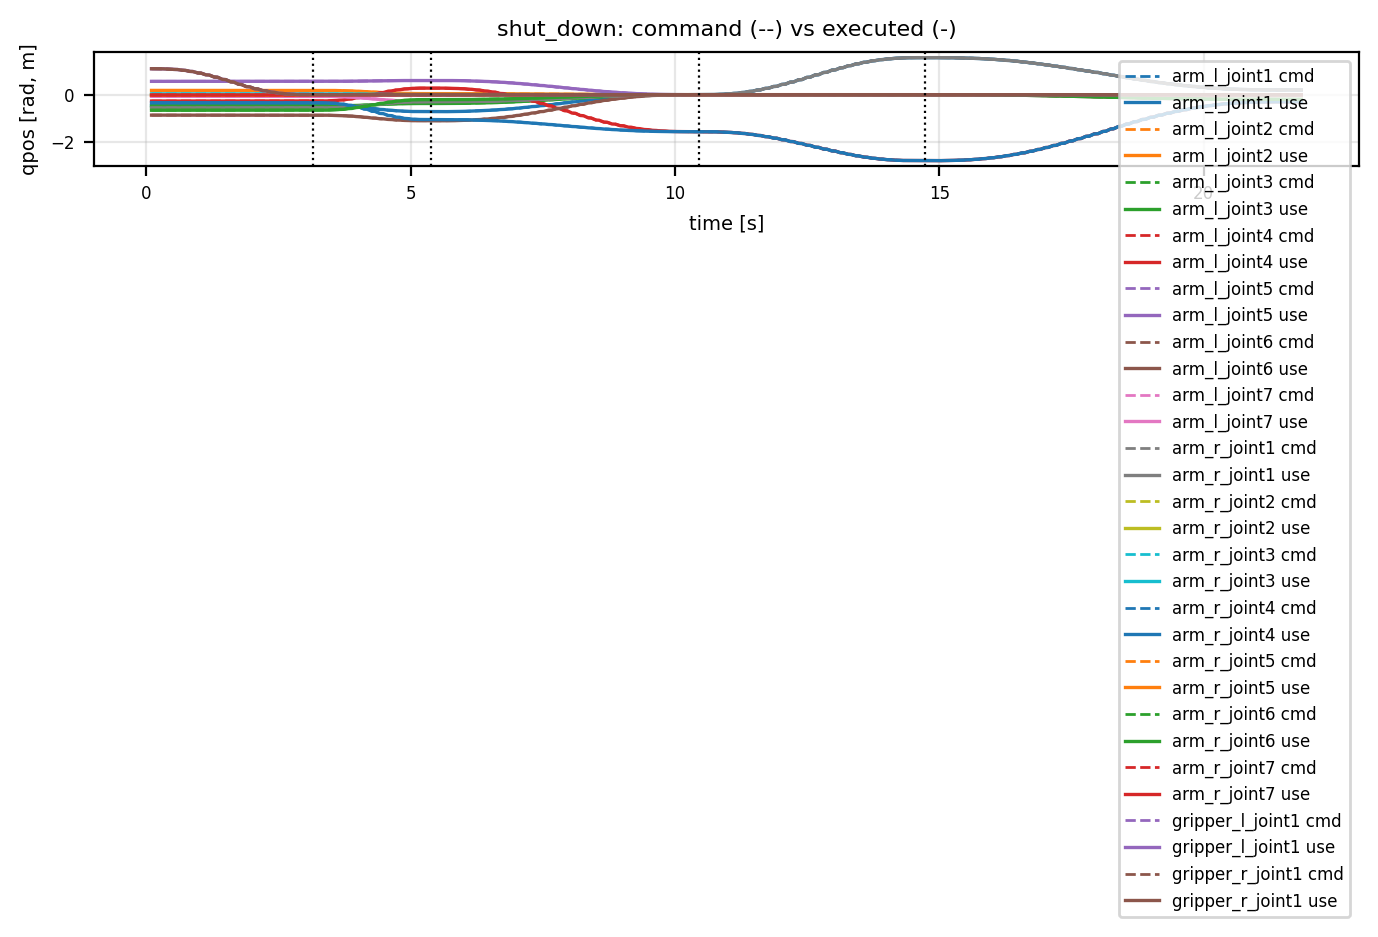

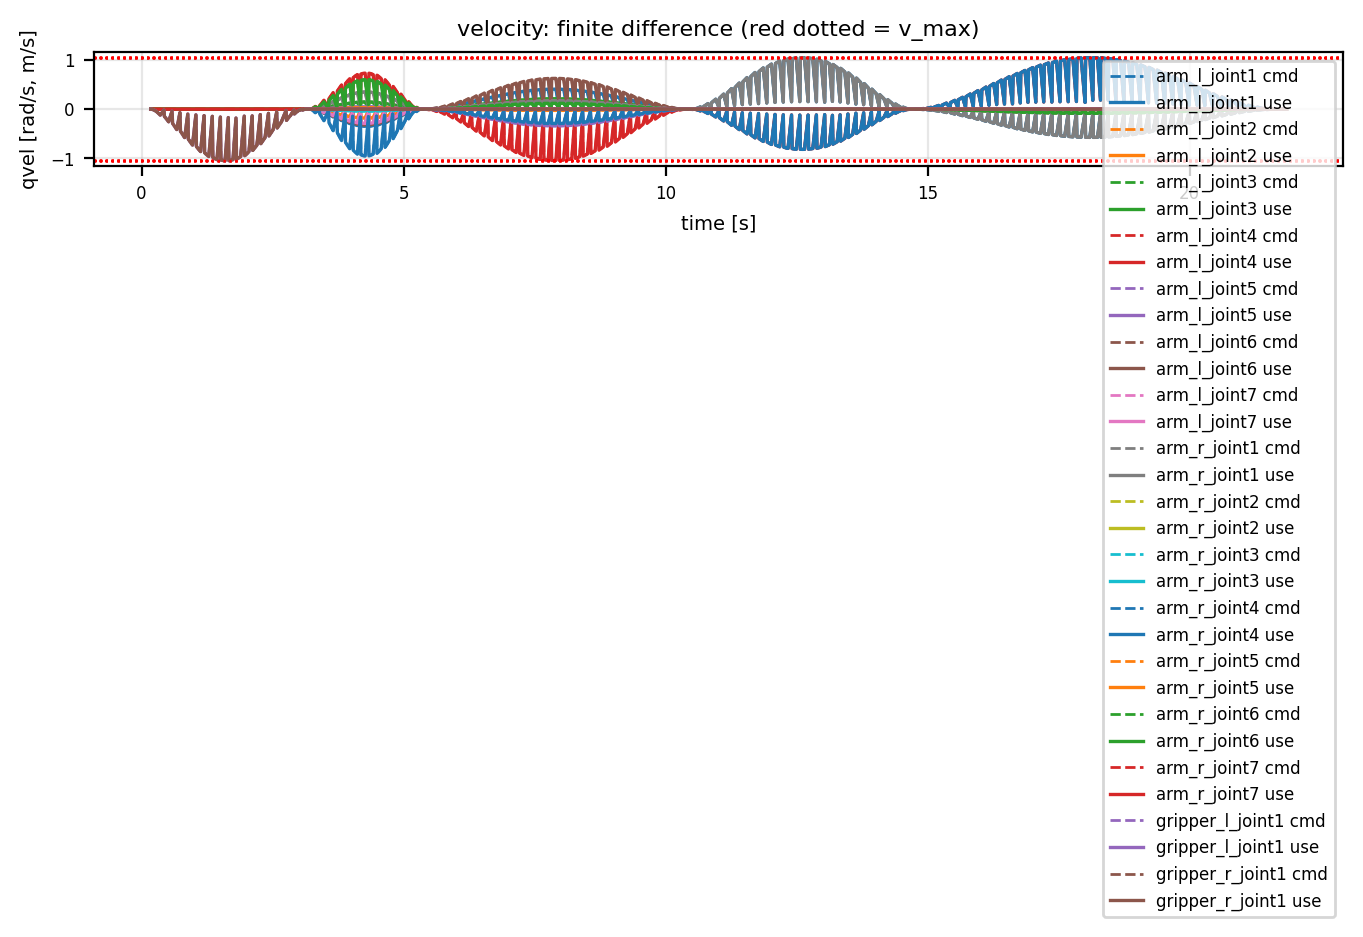

motion              : shut_down  (gripper_open -> wrist_lift -> step2 -> step1 -> start)
ticks               : 1405 over 21.84 s
loop timing         : dt median 10.0 ms (nominal 10.0 ms) -> effective 100.0 Hz
rate limit engaged  : 0 / 1405 ticks (0.0%), max dq/dq_max 1.000x
joint limit clipped : 0 / 1405 ticks (0.0%)

joint                 max |cmd-use|       deg / mm
lift_joint                0.000e+00      0.0000 mm
arm_r_joint7              0.000e+00     0.0000 deg
arm_r_joint6              0.000e+00     0.0000 deg
arm_r_joint5              0.000e+00     0.0000 deg
arm_r_joint4              0.000e+00     0.0000 deg

verdict: OK -- the planned trajectory respected both limits on its own.


In [7]:
# Analysis -- per-joint position/velocity plots, and the two clipping stages kept apart

if len(exec_log["t"]) < 3:
    raise RuntimeError("No motion logged. Run the loop cell and trigger a Motion command first.")

log_t     = np.array(exec_log["t"], dtype=np.float64)
log_q_cmd = np.array(exec_log["q_cmd"], dtype=np.float64)
log_q_use = np.array(exec_log["q_use"], dtype=np.float64)
log_dt    = np.array(exec_log["dt"], dtype=np.float64)

# Finite-difference velocity, using each tick's own dt rather than a nominal 1/hz.
dt_step = np.maximum(np.diff(log_t), 1e-9)[:, None]
qv_use  = np.diff(log_q_use, axis=0) / dt_step
qv_cmd  = np.diff(log_q_cmd, axis=0) / dt_step

# Plot only the joints that actually moved; all 19 at once is unreadable.
moved_idxs = np.where(np.max(np.abs(log_q_use - log_q_use[0]), axis=0) > 1e-6)[0]
if len(moved_idxs) == 0:
    moved_idxs = np.arange(min(2, log_q_use.shape[1]))

# Segment boundaries, so a multi-waypoint motion is readable.
segment_bounds = [(exec_log["segment"][i], log_t[i]) for i in range(1, len(log_t))
                  if exec_log["segment"][i] != exec_log["segment"][i - 1]]

# ---------------------------------------------------------------------------
# 1) Position
# ---------------------------------------------------------------------------
plt.figure(figsize=(7, 3))
for idx in moved_idxs:
    line, = plt.plot(log_t, log_q_cmd[:, idx], '--', lw=1.0,
                     label=f"{command_joint_names[idx]} cmd")
    plt.plot(log_t, log_q_use[:, idx], '-', lw=1.2, color=line.get_color(),
             label=f"{command_joint_names[idx]} use")
for name, t_edge in segment_bounds:
    plt.axvline(t_edge, color='k', ls=':', lw=0.8)
plt.xlabel("time [s]", fontsize=7); plt.ylabel("qpos [rad, m]", fontsize=7)
plt.title(f"{exec_log_label}: command (--) vs executed (-)", fontsize=8)
plt.legend(fontsize=6); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------------
# 2) Velocity, with the limit drawn in
# ---------------------------------------------------------------------------
plt.figure(figsize=(7, 3))
for idx in moved_idxs:
    line, = plt.plot(log_t[1:], qv_cmd[:, idx], '--', lw=1.0,
                     label=f"{command_joint_names[idx]} cmd")
    plt.plot(log_t[1:], qv_use[:, idx], '-', lw=1.2, color=line.get_color(),
             label=f"{command_joint_names[idx]} use")
    plt.axhline( joint_speed_limits[idx], color='r', ls=':', lw=0.8)
    plt.axhline(-joint_speed_limits[idx], color='r', ls=':', lw=0.8)
plt.xlabel("time [s]", fontsize=7); plt.ylabel("qvel [rad/s, m/s]", fontsize=7)
plt.title("velocity: finite difference (red dotted = v_max)", fontsize=8)
plt.legend(fontsize=6); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# ---------------------------------------------------------------------------
# 3) The two clipping stages, reported separately
# ---------------------------------------------------------------------------
n_tick    = len(log_t)
n_limited = int(np.sum(exec_log["limited"]))
n_clipped = int(np.sum(exec_log["clipped"]))
gap       = np.abs(log_q_cmd - log_q_use)

print(f"motion              : {exec_log_label}  ({' -> '.join(dict.fromkeys(exec_log['segment']))})")
print(f"ticks               : {n_tick} over {log_t[-1]:.2f} s")
print(f"loop timing         : dt median {1e3 * np.median(log_dt):.1f} ms "
      f"(nominal {1e3 / play_hz:.1f} ms) -> effective {1.0 / np.median(log_dt):.1f} Hz")
print(f"rate limit engaged  : {n_limited} / {n_tick} ticks ({100.0 * n_limited / n_tick:.1f}%), "
      f"max dq/dq_max {np.max(exec_log['dq_ratio']):.3f}x")
print(f"joint limit clipped : {n_clipped} / {n_tick} ticks ({100.0 * n_clipped / n_tick:.1f}%)")
print()
print(f"{'joint':<20s} {'max |cmd-use|':>14s} {'deg / mm':>14s}")
pri_joint_name_set = set(env.pri_joint_names)
for idx in np.argsort(-np.max(gap, axis=0))[:5]:
    value = float(np.max(gap[:, idx]))
    unit  = f"{1e3 * value:10.4f} mm" if command_joint_names[idx] in pri_joint_name_set \
            else f"{np.rad2deg(value):10.4f} deg"
    print(f"{command_joint_names[idx]:<20s} {value:14.3e} {unit:>14s}")

print()
if n_clipped > 0:
    print("verdict: the GOAL was out of range -- np.clip truncated it. "
          "Fix the waypoint; the offline check cell names the joint.")
elif n_limited > 0:
    print("verdict: the RATE LIMIT engaged -- the loop fell behind and dt hit the executor's "
          f"ceiling ({1e3 * executor.dt_max:.0f} ms). Lower render_hz.")
else:
    print("verdict: OK -- the planned trajectory respected both limits on its own.")